# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

## Step 1: Goal and Metric

**Goal:** predict the sale price of a house in King County from its attributes, and beat both a mean baseline and a simple rule-based baseline.

**Main metric: RMSE (root mean squared error, in $).** I use it to compare, tune and choose the models. We assume the model is used by a bank that lends money based on the estimated value of a house: overestimating one villa by $500k costs the bank far more than many small errors. RMSE squares every error before averaging, so large errors weigh much more than small ones (e.g. ten errors of $100k and nine of $50k plus one of $550k have the same MAE of $100k, but an RMSE of $100k vs. $180k). RMSE is also in dollars, so it can be compared directly with the baselines.

**Reported alongside:**
- **MAE (mean absolute error, in $):** the typical error in dollars, less driven by a few expensive houses. If MAE and RMSE differ a lot, a few large errors dominate.
- **R²:** the share of the price variation the model explains, without a unit, for communicating the result. It is not used for choosing, because on the same data it ranks models exactly like RMSE.

## Step 2: Get the Data

`01_loading_the_data_dominic.ipynb` combined the two tables (one row per sale, 21,597 sales) and saved the result as `data/eda.csv`. Run it first: the file is generated, not stored in git.

In [4]:
## Step 2: Get the data. The merged table was saved by 01_loading_the_data_dominic.ipynb.
df = pd.read_csv("data/eda.csv")
print(f"{df.shape[0]} rows, {df.shape[1]} columns")
df.head()

21597 rows, 23 columns


,date,price,house_id,id,id_details,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.0,7129300520,1,7129300520,3.0,1.00,1180.0,5650.0,1.0,...,7,1180.0,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0
1,2014-12-09,538000.0,6414100192,2,6414100192,3.0,2.25,2570.0,7242.0,2.0,...,7,2170.0,400.0,1951,1991.0,98125,47.7210,-122.319,1690.0,7639.0
2,2015-02-25,180000.0,5631500400,3,5631500400,2.0,1.00,770.0,10000.0,1.0,...,6,770.0,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0
3,2014-12-09,604000.0,2487200875,4,2487200875,4.0,3.00,1960.0,5000.0,1.0,...,7,1050.0,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0
4,2015-02-18,510000.0,1954400510,5,1954400510,3.0,2.00,1680.0,8080.0,1.0,...,8,1680.0,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0


## Step 3: Train-Test Split by House

176 houses were sold more than once. With a plain row-wise `train_test_split`, some of them would land in both sets (63 houses, 1.5% of the test sales), so the model would be tested on houses it had already seen with a price during training, a mild form of data leakage. I therefore split the **houses**, not the sales: `train_test_split` is used once on the list of `house_id`s, and every sale goes to the side of its house. For the same reason, cross-validation later uses `GroupKFold` with `house_id` as the group, so that no house appears in a training fold and its validation fold at the same time.

In [5]:
## Step 3: Split once, by house: all sales of one house go to the same side,
# so the model is never tested on a house it has already seen with a price.
houses = df["house_id"].unique()
train_houses, test_houses = train_test_split(houses, test_size=0.2, random_state=42)

df_train = df[df["house_id"].isin(train_houses)]
df_test = df[df["house_id"].isin(test_houses)]

print(f"houses: {len(train_houses)} train, {len(test_houses)} test")
print(f"sales:  train {df_train.shape}, test {df_test.shape} ({len(df_test) / len(df):.1%} of all sales)")
assert len(df_train) + len(df_test) == len(df), "every sale must land on exactly one side"
assert not set(df_train["house_id"]) & set(df_test["house_id"]), "no house on both sides"

houses: 17136 train, 4284 test
sales:  train (17270, 23), test (4327, 23) (20.0% of all sales)


## Step 4: Explore the Training Set

Everything in this step uses `df_train` only; `df_test` stays untouched until step 8. The task asks four questions: which values are missing, how the price and the features are distributed, which columns are related to the price, and which features contain the same information. Every finding ends with a consequence for the next steps.

yr_renovated    3097 missing (17.9%), median price missing $450,000 vs present $450,000
waterfront      1914 missing (11.1%), median price missing $445,000 vs present $451,000
sqft_basement    353 missing ( 2.0%), median price missing $449,000 vs present $450,000
view              52 missing ( 0.3%), median price missing $489,975 vs present $450,000


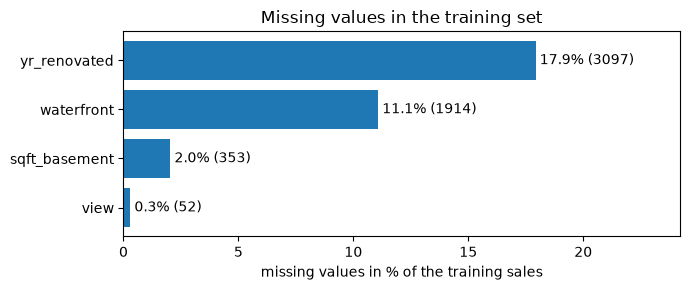

In [6]:
## Step 4: explore the TRAINING set only. First: which columns have gaps, and how large?
missing = df_train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
share = missing / len(df_train) * 100

# Does the price differ between rows with and without the value? If not, the gaps look random.
for col in missing.index:
    price_missing = df_train.loc[df_train[col].isna(), "price"].median()
    price_present = df_train.loc[df_train[col].notna(), "price"].median()
    print(f"{col:14} {missing[col]:5} missing ({share[col]:4.1f}%), "
          f"median price missing ${price_missing:,.0f} vs present ${price_present:,.0f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(share.index, share.values)
for i, col in enumerate(share.index):
    ax.text(share[col], i, f" {share[col]:.1f}% ({missing[col]})", va="center")
ax.invert_yaxis()
ax.set_xlim(0, share.max() * 1.35)
ax.set_xlabel("missing values in % of the training sales")
ax.set_title("Missing values in the training set")
plt.tight_layout()
plt.show()

**What we see:** Four columns have gaps: `yr_renovated` (17.9%), `waterfront` (11.1%), `sqft_basement` (2.0%) and `view` (0.3%). The median price is almost the same whether a value is missing or not (e.g. $450,000 vs. $450,000 for `yr_renovated`; the $40,000 gap for `view` rests on only 52 rows), so the gaps look random (MCAR) and need no extra "missing" indicator. **Consequences:**
- `sqft_basement` can be filled exactly: in every complete row `sqft_living = sqft_above + sqft_basement`, so a gap is `sqft_living - sqft_above`. This is a fixed rule that learns nothing, so it is a hand change (applied to the test set in step 8 as well).
- `waterfront` and `view` are 0 for the vast majority of houses: they are filled with the most frequent value inside the pipeline, which learns it from the training folds only.
- `yr_renovated` uses 0 for "never renovated"; a missing value most likely means the same.

count      17270.0
mean      542521.0
std       372193.0
min        78000.0
25%       324500.0
50%       450000.0
75%       649950.0
max      7700000.0
Name: price, dtype: float64
skew price: 4.20, skew log(price): 0.44
sales above $1 million: 1169 (6.8%)


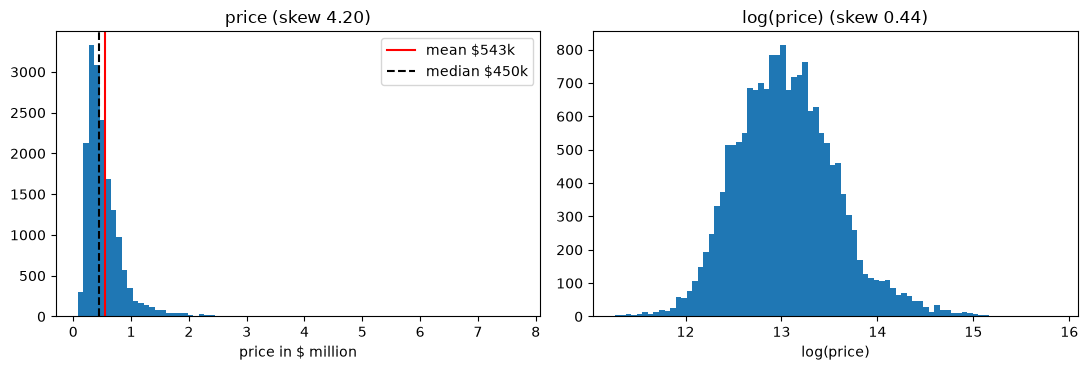

In [7]:
# The target: how is the price distributed, and does a log make it more symmetric?
price = df_train["price"]
print(price.describe().round(0))
print(f"skew price: {price.skew():.2f}, skew log(price): {np.log(price).skew():.2f}")
print(f"sales above $1 million: {(price > 1e6).sum()} ({(price > 1e6).mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(price / 1e6, bins=80)
axes[0].axvline(price.mean() / 1e6, color="red", label=f"mean ${price.mean() / 1e3:.0f}k")
axes[0].axvline(price.median() / 1e6, color="black", ls="--", label=f"median ${price.median() / 1e3:.0f}k")
axes[0].set_xlabel("price in $ million")
axes[0].set_title(f"price (skew {price.skew():.2f})")
axes[0].legend()
axes[1].hist(np.log(price), bins=80)
axes[1].set_xlabel("log(price)")
axes[1].set_title(f"log(price) (skew {np.log(price).skew():.2f})")
plt.tight_layout()
plt.show()

**What we see:** The price is strongly right-skewed (skew 4.20): the median is $450,000, but the mean is $542,521, because a long tail of expensive houses (up to $7.7 million; 6.8% above $1 million) pulls it up. After a log, the distribution is almost symmetric (skew 0.44). **Consequences:** the few expensive houses will drive the RMSE, so the largest errors in step 8 are expected among them. The training RMSE of the mean baseline equals the standard deviation of the price, about $372,000: the number every model has to beat. A model on `log(price)` is a candidate for step 7, but its predictions have to be converted back to dollars before scoring.

               pearson  spearman  mutual_info
grade            0.670     0.659        0.346
sqft_living      0.702     0.645        0.344
sqft_living15    0.587     0.577        0.270
sqft_above       0.605     0.541        0.261
bathrooms        0.526     0.498        0.204
lat              0.301     0.452        0.343
bedrooms         0.317     0.347        0.083
floors           0.251     0.317        0.077
view             0.395     0.295        0.057
sqft_basement    0.328     0.254        0.074
waterfront       0.272     0.123        0.009
yr_renovated     0.138     0.109        0.001
yr_built         0.053     0.101        0.073
sqft_lot         0.094     0.088        0.060
sqft_lot15       0.089     0.076        0.079
long             0.021     0.065        0.121
condition        0.032     0.015        0.004
zipcode         -0.054    -0.011        0.410


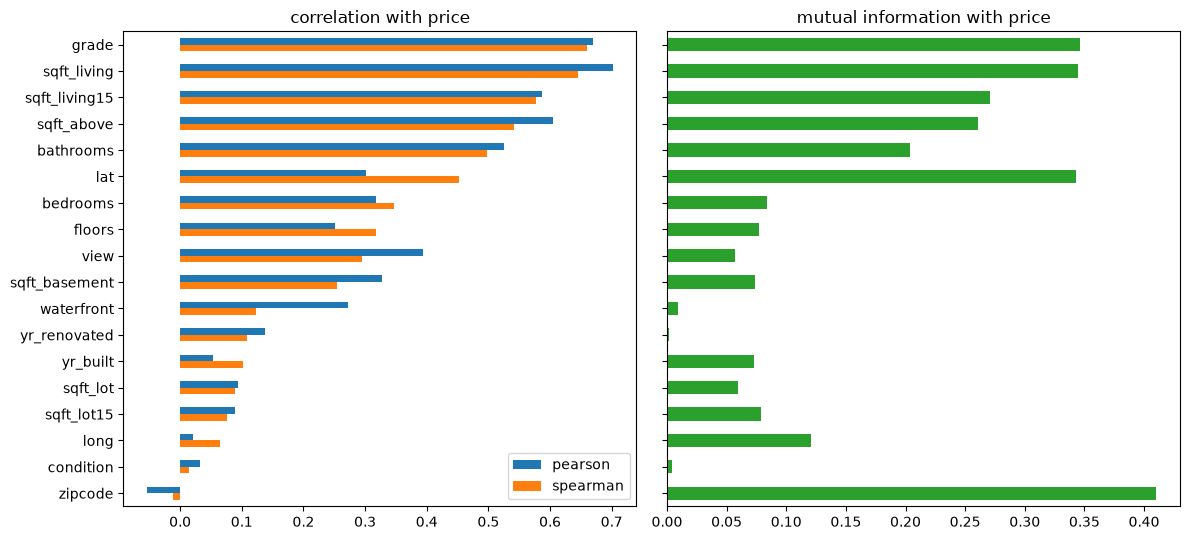

In [8]:
from sklearn.feature_selection import mutual_info_regression

# Which columns move with the price? Pearson sees straight lines, Spearman any rising/falling
# trend (ranks), mutual information any dependence, even U-shapes (W3D2 3.2).
ids = ["id", "house_id", "id_details", "date"]
features = [c for c in df_train.columns if c not in ids + ["price"]]
num = df_train[features + ["price"]]

relation = pd.DataFrame({
    "pearson": num.corr(method="pearson")["price"].drop("price"),
    "spearman": num.corr(method="spearman")["price"].drop("price"),
})
# MI cannot handle NaN: fill the gaps with the median for this look only (not a model step)
X_mi = df_train[features].fillna(df_train[features].median())
relation["mutual_info"] = mutual_info_regression(X_mi, df_train["price"], random_state=42)
relation = relation.sort_values("spearman", ascending=False)
print(relation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
relation[["pearson", "spearman"]].plot.barh(ax=axes[0])
axes[0].set_title("correlation with price")
relation["mutual_info"].plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title("mutual information with price")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

**What we see:** `sqft_living` (Pearson 0.70) and `grade` (0.67) are most strongly related to the price; `sqft_living` is the strongest column, so the rule-based baseline in step 5 is built from it. Mutual information measures how much knowing a feature reduces the uncertainty about the price, in any form (straight line, curve or one price level per group), but without a sign. **`zipcode`** shows why this matters: its correlation with the price is almost 0, yet its mutual information is the highest of all (0.41). The zip codes are labels without an order, so no straight line runs through them, but the location strongly decides the price (median prices per zip code range from $230,000 to $1,915,000). `lat` shows the same pattern on a smaller scale (Pearson 0.30, MI 0.34). **Consequence:** `zipcode` goes into the model one-hot encoded, not as a number. Mutual information looks at one feature at a time, so whether the zip code adds information *on top of* size and quality is checked later with cross-validation.

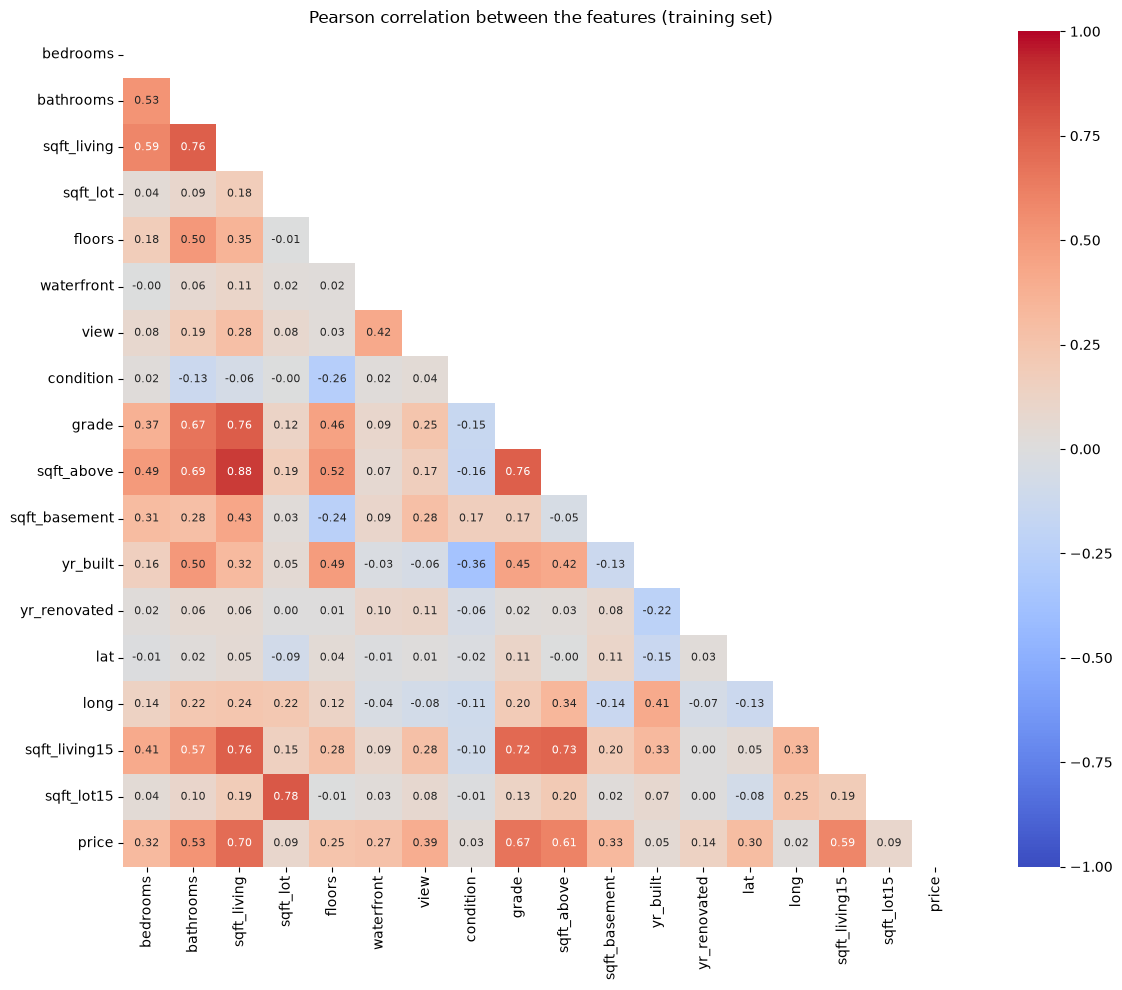

pearson: strongest feature pairs
sqft_above     sqft_living    0.88
sqft_lot15     sqft_lot       0.78
grade          sqft_living    0.76
sqft_living15  sqft_living    0.76
sqft_above     grade          0.76
sqft_living    bathrooms      0.76 



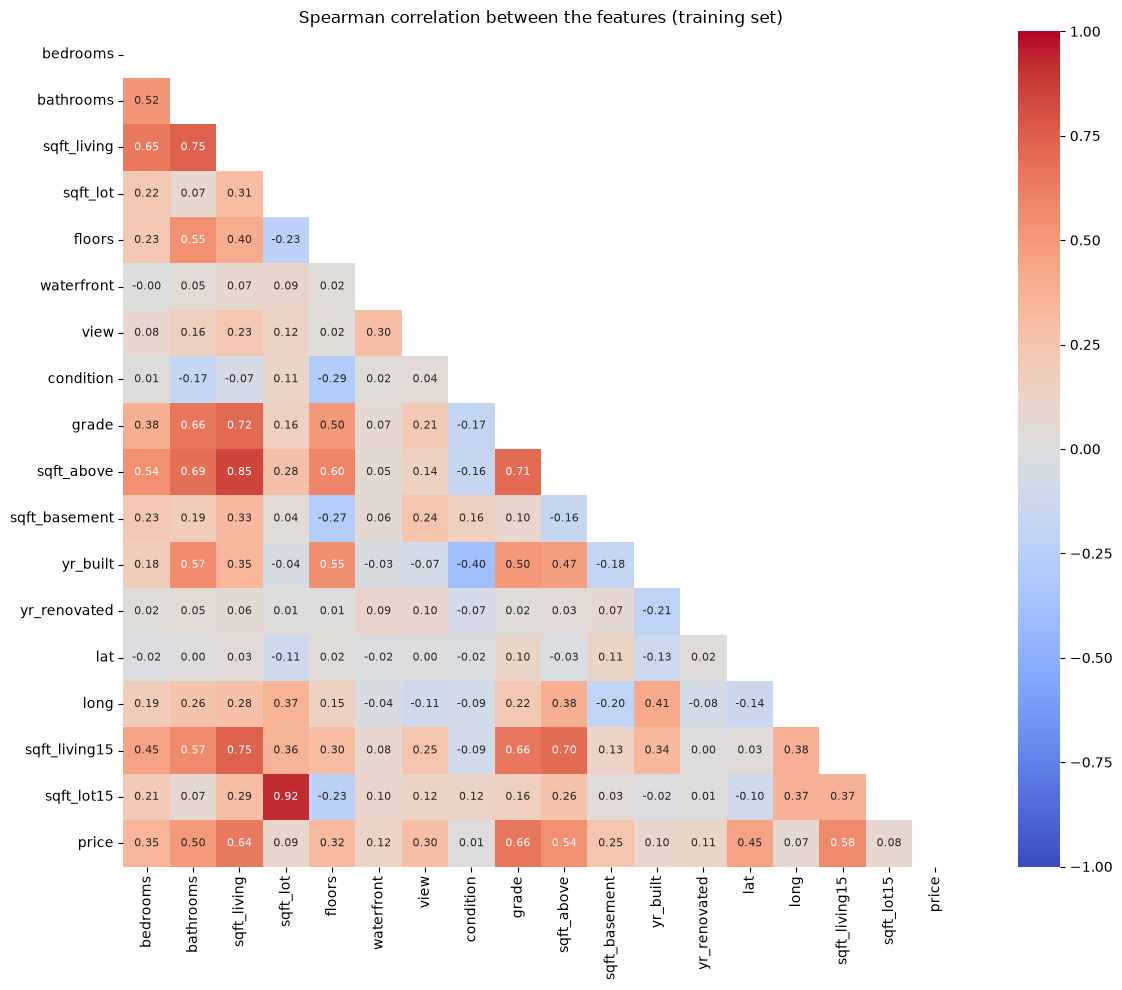

spearman: strongest feature pairs
sqft_lot15     sqft_lot       0.92
sqft_above     sqft_living    0.85
sqft_living15  sqft_living    0.75
sqft_living    bathrooms      0.75
grade          sqft_living    0.72
sqft_above     grade          0.71 



In [10]:
# Correlations between the features themselves: which columns carry the same information?
# zipcode is left out, its numbers are labels, so a correlation with it means nothing.
cols = [c for c in features if c != "zipcode"] + ["price"]
mask = np.triu(np.ones((len(cols), len(cols)), dtype=bool))  # hide the mirrored upper half

for method in ["pearson", "spearman"]:
    corr = df_train[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(13, 10))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8},
                cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation between the features (training set)")
    plt.tight_layout()
    plt.show()

    # The strongest pairs, without price and without each column with itself
    pairs = corr.drop(index="price", columns="price").where(~mask[:-1, :-1]).stack()
    print(f"{method}: strongest feature pairs")
    print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string(), "\n")

**What we see:** Several features carry largely the same information, a "size cluster" around `sqft_living`:

| Pair | Pearson | Spearman | Why |
|:--|--:|--:|:--|
| `sqft_above` – `sqft_living` | 0.88 | 0.85 | `sqft_above` is part of `sqft_living` |
| `sqft_lot15` – `sqft_lot` | 0.78 | 0.92 | large lots lie next to large lots |
| `grade` – `sqft_living` | 0.76 | 0.72 | large houses tend to be built to a higher standard |
| `sqft_living15` – `sqft_living` | 0.76 | 0.75 | large houses stand next to large houses |
| `bathrooms` – `sqft_living` | 0.76 | 0.75 | more space, more bathrooms |

Pearson measures straight-line relationships, Spearman any consistently rising or falling one (it uses ranks). For `sqft_lot`, Spearman is much higher than Pearson (0.92 vs. 0.78): a few huge lots disturb the straight line but not the order, a sign of a skewed column. **Consequence:** Ridge spreads the weight over correlated features, so nothing has to be dropped for prediction, but single coefficients from this cluster cannot be read as the effect of one feature alone. The exact dependency `sqft_living = sqft_above + sqft_basement` is not visible in pairs; it is checked with the VIF below.

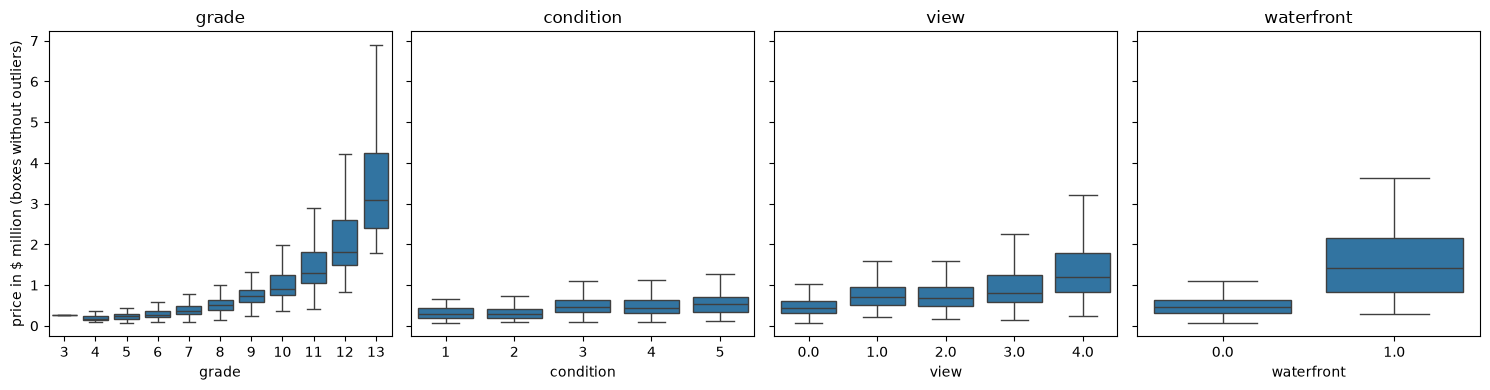

grade      {3: 1, 4: 19, 5: 198, 6: 1601, 7: 7147, 8: 4848, 9: 2109, 10: 924, 11: 331, 12: 80, 13: 12}
condition  {1: 26, 2: 129, 3: 11228, 4: 4515, 5: 1372}
view       {0.0: 15541, 1.0: 267, 2.0: 750, 3.0: 404, 4.0: 256}
waterfront {0.0: 15233, 1.0: 123}
zipcodes: 70, median price from $230,000 to $1,915,000
Pearson zipcode vs price (meaningless, the numbers are labels): -0.054


In [9]:
# Columns stored as numbers that are really categories: compare the price per group.
# Ordinal ones (grade, condition, view) should rise step by step; waterfront is yes/no.
cat_cols = ["grade", "condition", "view", "waterfront"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, cat_cols):
    sns.boxplot(x=df_train[col], y=df_train["price"] / 1e6, ax=ax, showfliers=False)
    ax.set_title(col)
axes[0].set_ylabel("price in $ million (boxes without outliers)")
plt.tight_layout()
plt.show()

# How many sales per group? Small groups give unreliable boxes.
for col in cat_cols:
    print(f"{col:10}", df_train[col].value_counts().sort_index().to_dict())

# zipcode: 70 groups, too many for boxes. How far apart are the median prices?
zip_median = df_train.groupby("zipcode")["price"].median()
print(f"zipcodes: {zip_median.size}, median price from ${zip_median.min():,.0f} to ${zip_median.max():,.0f}")
print(f"Pearson zipcode vs price (meaningless, the numbers are labels): "
      f"{df_train['zipcode'].corr(df_train['price']):.3f}")

**What we see:** `grade` raises the price not by the same amount per step but faster and faster (roughly +$150k from grade 7 to 8, over +$1 million from 12 to 13); grades 3 and 13 have only 1 and 12 sales, so their boxes are unreliable. `condition` hardly matters beyond the jump from 1-2 to 3, and 11,228 of 17,270 houses have condition 3. `view` jumps from 0 to 1 and then rises slowly. Waterfront houses cost about three times as much (median about $1.4 million vs. $450,000), but there are only 123 of them. Pearson between `zipcode` and the price is -0.05, although the median price per zip code varies by a factor of 8. **Consequences:** `grade`, `condition` and `view` stay numeric (ordinal, more is better), but the accelerating effect of `grade` argues for polynomial features or a log target in step 7. Waterfront and luxury houses are where the largest errors are expected in step 8. `zipcode` is one-hot encoded.

                skew  skew_after_log1p
sqft_lot       13.01              0.93
sqft_lot15      9.94              0.94
sqft_basement   1.60              0.48
sqft_living     1.52             -0.02
sqft_above      1.48              0.27
sqft_living15   1.10              0.21
floors          0.60              0.36
bathrooms       0.54             -0.22
bedrooms        0.52             -0.34


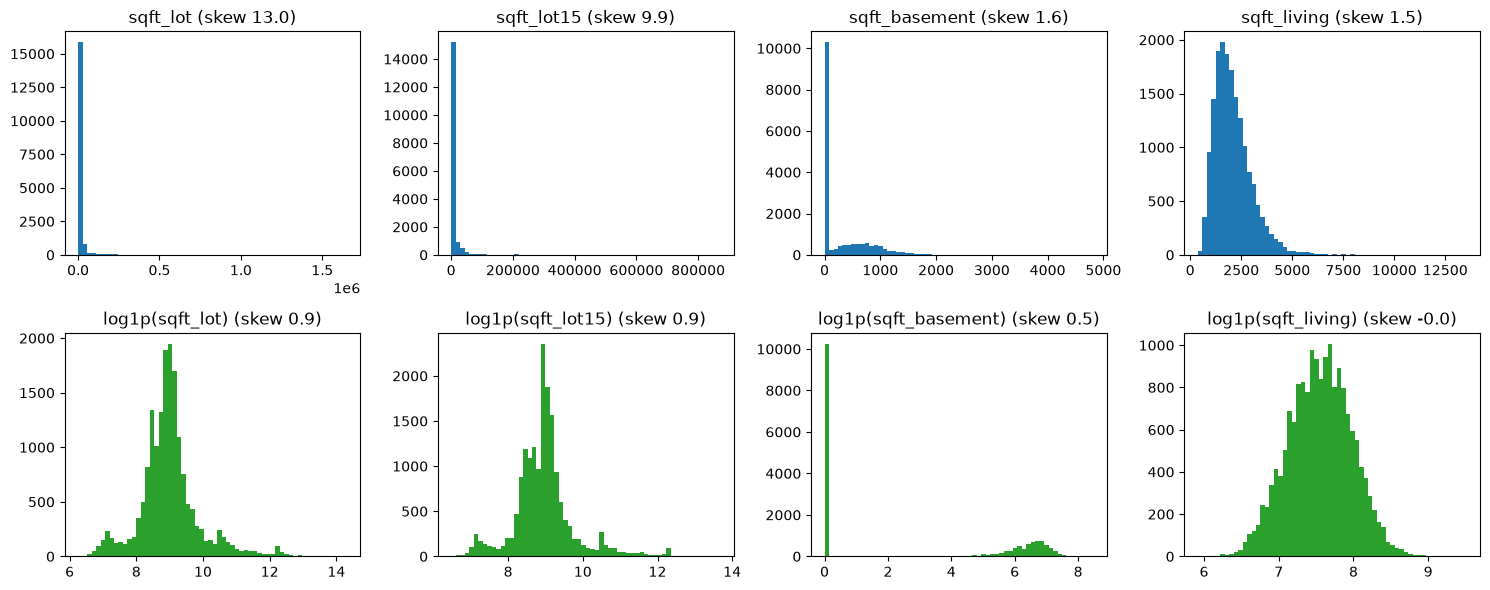

share of houses without basement: 0.594


In [9]:
# Which numeric features are right-skewed, and does log1p make them more symmetric?
# Category-like columns (grade, condition, view, waterfront, zipcode) and the years are left out.
continuous = ["sqft_living", "sqft_above", "sqft_basement", "sqft_lot",
              "sqft_living15", "sqft_lot15", "bedrooms", "bathrooms", "floors"]
skew = pd.DataFrame({
    "skew": df_train[continuous].skew(),
    "skew_after_log1p": np.log1p(df_train[continuous]).skew(),
}).sort_values("skew", ascending=False)
print(skew.round(2))

top = skew.index[:4]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, col in enumerate(top):
    axes[0, i].hist(df_train[col].dropna(), bins=60)
    axes[0, i].set_title(f"{col} (skew {skew.loc[col, 'skew']:.1f})")
    axes[1, i].hist(np.log1p(df_train[col].dropna()), bins=60, color="tab:green")
    axes[1, i].set_title(f"log1p({col}) (skew {skew.loc[col, 'skew_after_log1p']:.1f})")
plt.tight_layout()
plt.show()
print("share of houses without basement:", (df_train["sqft_basement"] == 0).mean().round(3))

**What we see:** `sqft_lot` (skew 13.0) and `sqft_lot15` (9.9) are extremely right-skewed: most lots are small, a few are huge (up to 1.6 million sqft). After `log1p` their skew drops below 1. `sqft_basement` should not be logged: 59.4% of the houses have no basement, so the log only produces a spike at 0 next to a hill. `sqft_living` (skew 1.5) would become symmetric with a log, but its relationship with the price in dollars is close to a straight line (Pearson 0.70 is even higher than Spearman 0.65), and a log would bend it. For a linear model, what matters is the relationship with the target, not the shape of a feature on its own. **Consequences:** `log1p` for `sqft_lot` and `sqft_lot15` inside the pipeline; a yes/no feature `has_basement`; `sqft_living` stays as it is (can be checked with cross-validation in step 6).

In [10]:
from sklearn.linear_model import LinearRegression

# VIF: can a feature be predicted from all the others? VIF = 1 / (1 - R²) (W3D2 3.3).
# Rows with gaps are left out for this check only.
vif_cols = [c for c in features if c != "zipcode"]
X_vif = df_train[vif_cols].dropna()

def vif(X, col):
    others = X.drop(columns=col)
    r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
    return np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)

# sqft_living = sqft_above + sqft_basement exactly, so one of the three has to go: which one?
for dropped in [None, "sqft_basement", "sqft_above"]:
    X = X_vif if dropped is None else X_vif.drop(columns=dropped)
    vifs = pd.Series({c: vif(X, c) for c in X.columns}).sort_values(ascending=False)
    print(f"dropped: {dropped}")
    print(vifs.round(1).head(4).to_string())
    print()

dropped: None
sqft_living      inf
sqft_basement    inf
sqft_above       inf
grade            3.5



dropped: sqft_basement
sqft_living    8.7
sqft_above     6.9
grade          3.5
bathrooms      3.3



dropped: sqft_above
sqft_living      6.1
grade            3.5
bathrooms        3.3
sqft_living15    3.0



**What we see:** With all three area columns, `sqft_living`, `sqft_above` and `sqft_basement` have an infinite VIF: each one can be calculated exactly from the other two (`sqft_living = sqft_above + sqft_basement`), which breaks the "no perfect multicollinearity" assumption. Dropping `sqft_above` is the better choice (highest remaining VIF 6.1 for `sqft_living`, against 8.7 when dropping `sqft_basement`), and it loses nothing, because `sqft_above = sqft_living - sqft_basement`. A VIF of 6.1 is above the rule of thumb of 5 but below 10; it is the size cluster from the heatmap, which Ridge can handle. **Consequence:** drop `sqft_above`.

In [11]:
# Plausibility: values that are allowed by type but impossible or suspicious in reality.
sale_year = pd.to_datetime(df_train["date"]).dt.year
renovated_after_sale = df_train["yr_renovated"] > sale_year
built_after_sale = df_train["yr_built"] > sale_year
print("date range:", df_train["date"].min(), "to", df_train["date"].max())
print("renovated after the sale:", renovated_after_sale.sum())
print("built after the sale:    ", built_after_sale.sum())
print("bedrooms:", df_train["bedrooms"].value_counts().sort_index().to_dict())
print("bathrooms == 0:", (df_train["bathrooms"] == 0).sum(), "| bedrooms == 0:", (df_train["bedrooms"] == 0).sum())
print("yr_renovated values > 0, min/max:", df_train.loc[df_train["yr_renovated"] > 0, "yr_renovated"].agg(["min", "max"]).to_dict())
print(df_train.loc[df_train["bedrooms"] >= 9, ["price", "bedrooms", "bathrooms", "sqft_living", "grade"]])
dup_houses = df_train.drop_duplicates("house_id").duplicated(subset=[c for c in features], keep=False).sum()
print("different house_id but identical attributes:", dup_houses)
age = sale_year - df_train["yr_built"]
print("age at sale min/max:", age.min(), age.max())

date range: 2014-05-02 to 2015-05-27
renovated after the sale: 5
built after the sale:     11
bedrooms: {1.0: 146, 2.0: 2191, 3.0: 7854, 4.0: 5515, 5.0: 1294, 6.0: 221, 7.0: 33, 8.0: 10, 9.0: 4, 10.0: 2}
bathrooms == 0: 0 | bedrooms == 0: 0
yr_renovated values > 0, min/max: {'min': 1940.0, 'max': 2015.0}
           price  bedrooms  bathrooms  sqft_living  grade
4231    700000.0       9.0       3.00       3680.0      7
6073   1280000.0       9.0       4.50       3650.0      8
8537    450000.0       9.0       7.50       4050.0      7
13301  1150000.0      10.0       5.25       4590.0      9
15147   650000.0      10.0       2.00       3610.0      7
16830  1400000.0       9.0       4.00       4620.0     11
different house_id but identical attributes: 8
age at sale min/max: -1 115


**What we see:** The sales run from 2 May 2014 to 27 May 2015. **5 houses were renovated after their sale:** a feature "renovated" that counted them would use information that did not exist when the price was paid (target leakage). **11 houses were built after their sale** (age -1): plausible, new houses are often sold before they are finished, so the age is set to 0 instead of being treated as an error. Bedrooms range from 1 to 10 with no zeros, and the houses with 9 or 10 bedrooms have 3,600 to 4,600 sqft, so there is no implausible outlier (unlike the 33 bedrooms in the Kaggle version). 8 houses have different `house_id`s but identical attributes, probably the same house registered twice; too few to change anything, noted as a known weakness.

### Hand Changes (applied to the training and the test set with `prepare()`)

These rules learn nothing from the data, so they can be applied row by row before the pipeline, and in step 8 exactly the same function is applied to `df_test`.

| # | Hand change | Reason |
|:--|:--|:--|
| 1 | fill missing `sqft_basement` with `sqft_living - sqft_above` | exact rule (missing values) |
| 2 | `sale_year` and `sale_month` from `date` | `date` as text is unusable; a seasonal effect is possible |
| 3 | `age_at_sale = sale_year - yr_built`, at least 0 | the age says more than the year of construction; 11 houses were sold before they were finished |
| 4 | `renovated = 1` if `0 < yr_renovated <= sale_year`, else 0 | no leakage: the 5 renovations after the sale do not count |
| 5 | `has_basement = 1` if `sqft_basement > 0` | 59% of the houses have no basement |
| 6 | drop `id`, `house_id`, `id_details`, `date`, `sqft_above`, `yr_built`, `yr_renovated` | identifiers carry no information; `sqft_above` (= living − basement) and `yr_built` (= sale year − age, VIF about 1.3 million) are redundant; `yr_renovated` is replaced by rule 4 |

**Inside the pipeline (learned on the training folds only, step 6):** most-frequent imputation for `waterfront` and `view`, `log1p` for `sqft_lot` and `sqft_lot15`, `StandardScaler` for the numeric columns, one-hot encoding for `zipcode`.

**Before rule 6 drops `house_id`:** keep it as `groups_train = df_train["house_id"]` for `GroupKFold` in steps 6 and 7.

In [11]:
def prepare(df):
    """Apply the hand changes (fixed rules, nothing learned) to a copy of df.
    The same function is applied to df_test in step 8."""
    df = df.copy()
    # 1: the basement is exactly the living area minus the area above ground
    df["sqft_basement"] = df["sqft_basement"].fillna(df["sqft_living"] - df["sqft_above"])
    # 2: date as text is unusable; year and month of the sale can carry a trend or a season
    sale_date = pd.to_datetime(df["date"])
    df["sale_year"] = sale_date.dt.year
    df["sale_month"] = sale_date.dt.month
    # 3: age at sale; houses sold before they were finished get age 0, not -1
    df["age_at_sale"] = (df["sale_year"] - df["yr_built"]).clip(lower=0)
    # 4: only renovations up to the sale count (later ones did not exist when the price was paid);
    #    a missing yr_renovated counts as "not renovated", like the 0s
    df["renovated"] = ((df["yr_renovated"] > 0) & (df["yr_renovated"] <= df["sale_year"])).astype(int)
    # 5: most houses have no basement, so "has one at all" is its own piece of information
    df["has_basement"] = (df["sqft_basement"] > 0).astype(int)
    # 6: identifiers, the raw date, redundant columns (sqft_above = living - basement,
    #    yr_built = sale_year - age_at_sale) and yr_renovated, replaced by rule 4
    return df.drop(columns=["id", "house_id", "id_details", "date",
                            "sqft_above", "yr_built", "yr_renovated"])

In [12]:
# Keep the house of every training sale for GroupKFold, before prepare() drops house_id.
groups_train = df_train["house_id"]

train_prepared = prepare(df_train)
print(f"before: {df_train.shape}, after: {train_prepared.shape}")
print("columns:", list(train_prepared.columns))
print("missing values left (handled by the pipeline):", train_prepared.isna().sum()[lambda s: s > 0].to_dict())
print(f"renovated: {train_prepared['renovated'].sum()}, has_basement: {train_prepared['has_basement'].mean():.1%}, "
      f"age_at_sale: {train_prepared['age_at_sale'].min()} to {train_prepared['age_at_sale'].max()}")
assert len(groups_train) == len(train_prepared)

before: (17270, 23), after: (17270, 21)
columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'age_at_sale', 'renovated', 'has_basement']
missing values left (handled by the pipeline): {'waterfront': 1914, 'view': 52}
renovated: 595, has_basement: 39.3%, age_at_sale: 0 to 115


**What we see:** `prepare()` turns the 23 columns into 21 (7 dropped, 5 new: `sale_year`, `sale_month`, `age_at_sale`, `renovated`, `has_basement`). The only gaps left are `waterfront` (1,914) and `view` (52), which the pipeline fills. 595 houses count as renovated: 600 have a renovation year, but 5 of them were renovated after the sale and correctly do not count. 39.3% of the houses have a basement, and the age at sale runs from 0 to 115 years. `groups_train` keeps the house of every training sale for `GroupKFold`, because `prepare()` drops `house_id`; the rows keep their order, so it matches `train_prepared` row by row.

## Step 5: Features, Target and Two Baselines

`X_train` and `y_train` are split from the prepared training set. Two simple models set the bar that every model in steps 6 and 7 has to beat: a **mean baseline** and a **rule-based baseline** built from `sqft_living`, the column most strongly related to the price in step 4 (Pearson 0.70; by Spearman, `grade` would be marginally ahead with 0.659 against 0.645, but the rule is a linear calculation, so Pearson is the fitting measure). The value of the rule is learned on the training set only and kept in a variable, so that step 8 applies it to the test set unchanged.

In [14]:
## Step 5: separate the features from the target (the test set stays untouched until step 8)
X_train = train_prepared.drop(columns="price")
y_train = train_prepared["price"]

# Mean baseline: predicts the mean training price for every house
mean_baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_mean = mean_baseline.predict(X_train)

# Rule-based baseline from sqft_living, the column most strongly related to the price (step 4):
# one number learned on train, the median price per square foot, times the living area
price_per_sqft = (y_train / X_train["sqft_living"]).median()
pred_rule = price_per_sqft * X_train["sqft_living"]

for name, pred in [("mean baseline", pred_mean), ("rule: median $/sqft", pred_rule)]:
    print(f"{name:20} train RMSE ${root_mean_squared_error(y_train, pred):>9,.0f}  "
          f"MAE ${mean_absolute_error(y_train, pred):>9,.0f}  R² {r2_score(y_train, pred):.3f}")
print(f"median price per sqft: ${price_per_sqft:,.2f}; std of price (ddof=0): ${y_train.std(ddof=0):,.0f}")

mean baseline        train RMSE $  372,183  MAE $  235,562  R² 0.000
rule: median $/sqft  train RMSE $  268,971  MAE $  168,793  R² 0.478
median price per sqft: $245.10; std of price (ddof=0): $372,183


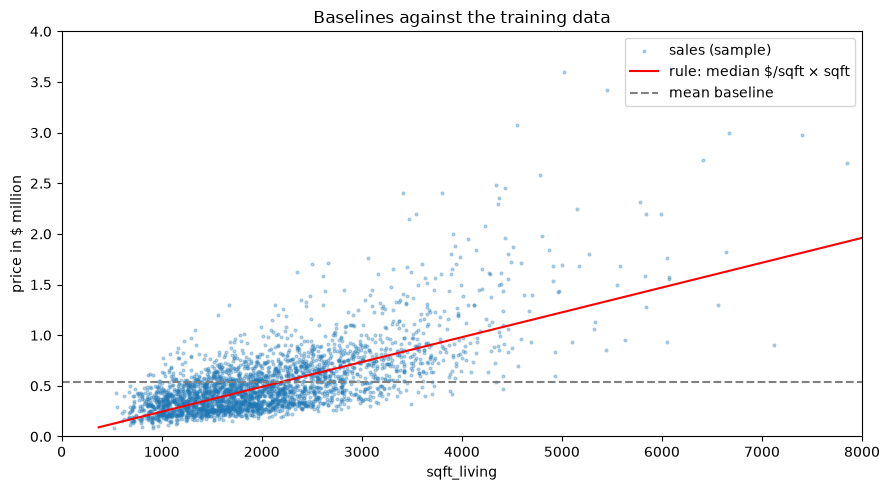

In [15]:
# What the rule looks like against the data (a sample of 3,000 sales, so the plot stays readable)
sample = X_train.sample(3000, random_state=42).index
order = X_train["sqft_living"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_train.loc[sample, "sqft_living"], y_train[sample] / 1e6, s=4, alpha=0.3, label="sales (sample)")
ax.plot(X_train.loc[order, "sqft_living"], pred_rule[order] / 1e6, color="red", label="rule: median $/sqft × sqft")
ax.axhline(y_train.mean() / 1e6, color="grey", ls="--", label="mean baseline")
ax.set_xlabel("sqft_living")
ax.set_ylabel("price in $ million")
ax.set_xlim(0, 8000)
ax.set_ylim(0, 4)
ax.set_title("Baselines against the training data")
ax.legend()
plt.tight_layout()
plt.show()

**What we see:**

| Baseline | Train RMSE | MAE | R² |
|:--|--:|--:|--:|
| mean | $372,183 | $235,562 | 0.000 |
| rule: median $/sqft × `sqft_living` | $268,971 | $168,793 | 0.478 |

The mean baseline behaves exactly as expected: its RMSE equals the standard deviation of the price and its R² is 0. The rule uses one number learned on the training set, a median price of **$245.10 per sqft**, and already explains almost half of the price variation. It is a straight line through the origin, so very small houses are slightly underestimated (the lot has a value, too), and the spread around the line grows with the size of the house. A rule with one median price per size decile was also tried: it scored worse (train RMSE $294,453), because its top group gives every house above about 3,300 sqft the same price, which underestimates the largest houses. **Consequence:** a model only counts as far as it beats **$268,971**.